<a href="https://colab.research.google.com/github/vtecftwy/utseus-dives/blob/main/nbs/intro_1_dl_w_tf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Deep Learning with Tensorflow

# 0. Imports and Setup

<p>In this notebook we will use the following python packages on Python 3.10.15:</p>
<ul>
<li><code>jupyter</code></li>
<li><code>matplotlib</code></li>
<li><code>numpy</code></li>
<li><code>pandas</code></li>
<li><code>pillow</code></li>
<li><code>scikit-learn</code></li>
<li><code>tensorflow</code></li>
</ul>

<details>
    <summary><i>List of Python packages with versions:<i></summary>
<p></br>The notebook was last tested with the following versions:</p>
<ul>
<li><code>jupyter==1.1.1</code></li>
<li><code>matplotlib==3.10.7</code></li>
<li><code>numpy==2.3.3</code></li>
<li><code>pandas==2.3.3</code></li>
<li><code>pillow==11.3.0</code></li>
<li><code>scikit-learn==1.8.0</code></li>
<li><code>tensorflow==2.21.0</code></li>
</ul>
</details>     

In [1]:
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
from tensorflow import __version__
print(f"TensorFlow version: {__version__}")

from pathlib import Path
import tensorflow as tf
from tensorflow import keras

I0000 00:00:1794305691.367835   42424 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.21.0


# 1. Overview

Building a deep learning model requires the following steps:
- Handle data - `datasets`
- Build the architecture - `model`
- Train the model using gthe architecture and the model
- Validate the trained model

We will first use a simple tabular data classification to show the mechanics of model building

# 2. Build a simple model with Tabular Data

## Dataset

In [2]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split
X, y = make_blobs(n_samples=5000, n_features=2, centers=4, cluster_std=1.5, random_state=88)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=88)

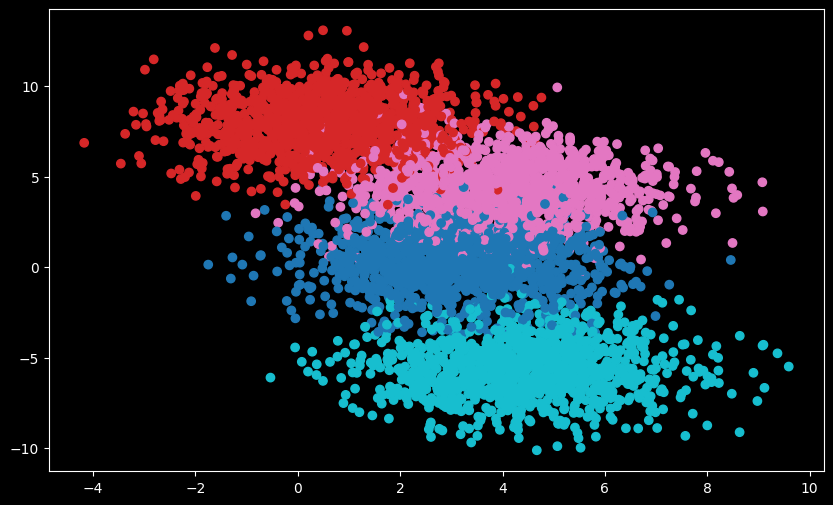

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='tab10');

Look at the 'shape' of the data

In [4]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((4000, 2), (4000,), (1000, 2), (1000,))

In [5]:
y_train[:5]

array([3, 3, 2, 1, 2])

Labels are integers (one for each of the 4 categories).

We need to convert this into one hot encoded values.

In [6]:
y_train_ohe =keras.utils.to_categorical(y_train, num_classes=4)
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=4)
y_train_ohe.shape, y_test_ohe.shape

((4000, 4), (1000, 4))

In [7]:
y_train_ohe[:5]

array([[0., 0., 0., 1.],
       [0., 0., 0., 1.],
       [0., 0., 1., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.]])

In [9]:
for i, ohe in zip(y_train[:5], y_test_ohe[:5]):
    print(f" - {i} -> {ohe}")

 - 3 -> [1. 0. 0. 0.]
 - 3 -> [0. 0. 1. 0.]
 - 2 -> [1. 0. 0. 0.]
 - 1 -> [0. 0. 0. 1.]
 - 2 -> [1. 0. 0. 0.]


## Architecture

We will build a small model that:
- input: takes the `X` as input (shape: many samples with 2 values each)
- outputs: gives 4 values (one for each class). Value between 0 and 1 and sum of values = 1

In [11]:
model = keras.Sequential(name='MLP')
model.add(keras.layers.Input(shape=(2,)))
model.add(keras.layers.Dense(8, activation='relu'))
model.add(keras.layers.Dense(4, activation='softmax'))
model.summary();

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60 (240.00 B)

 Trainable params: 60 (240.00 B)

 Non-trainable params: 0 (0.00 B)

Then we need to provide to the model the "tools" to learn:
- an optimiser (algorithm it will use to gradually converge to the correct parameters)
    - the optimiser can be parametrised to perform better
    - most important value to set is the learning rate
- a loss function (a measure of how wrong the model's predictions are) which will be minimized
- metrics (measure of performances humans will track)

In [12]:
opt = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=opt,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Training

Now we are ready with training, using our training dataset (`X_train` and `y_train_ohe`)

In [13]:
history = model.fit(
    X_train, y_train_ohe,
    validation_split=0.2,
    epochs=25,
    batch_size=32
)

Epoch 1/25


I0000 00:00:1794305789.817685   42877 service.cc:153] XLA service 0x7161a4030d10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794305789.817730   42877 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4080 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.1.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794305789.830509   42877 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794305789.884284   42877 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1794305789.891325   42877 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1037__.16


 58/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5448 - loss: 1.5165

I0000 00:00:1794305791.056670   42877 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6459 - loss: 1.1994 - val_accuracy: 0.7013 - val_loss: 0.9702
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7022 - loss: 0.8653 - val_accuracy: 0.7138 - val_loss: 0.7619
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7222 - loss: 0.6824 - val_accuracy: 0.7450 - val_loss: 0.6034
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7784 - loss: 0.5479 - val_accuracy: 0.8175 - val_loss: 0.4917
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8450 - loss: 0.4583 - val_accuracy: 0.8938 - val_loss: 0.4176
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8859 - loss: 0.4013 - val_accuracy: 0.9013 - val_loss: 0.3679
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8922 - loss: 0.3636 - val_accuracy: 0.9087 - val_loss: 0.3357
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8934 - loss: 0.3373 - val_accuracy: 0.9112 - val_

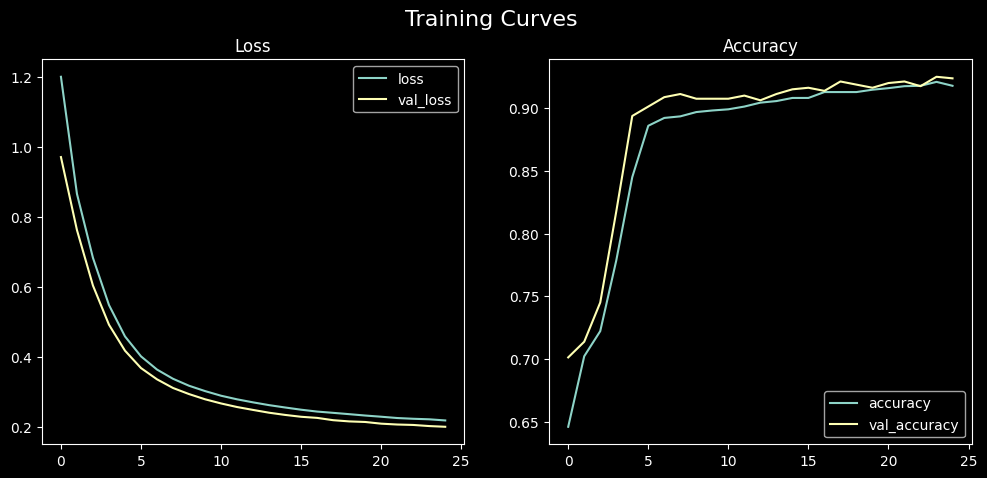

In [14]:
pd.DataFrame(history.history).columns
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(12,5))
pd.DataFrame(history.history).loc[:,['loss', 'val_loss']].plot(ax=ax1, title='Loss');  
pd.DataFrame(history.history).loc[:, ['accuracy', 'val_accuracy']].plot(ax=ax2, title='Accuracy');
fig.suptitle('Training Curves', fontsize=16);

## Evaluation 

Now we test the model with data that were not used for training: `X_test`, `y_test_ohe`

In [15]:
model.evaluate(X_test, y_test_ohe)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9060 - loss: 0.2308


[0.23080766201019287, 0.906000018119812]

# Build another model with more complex tabular data

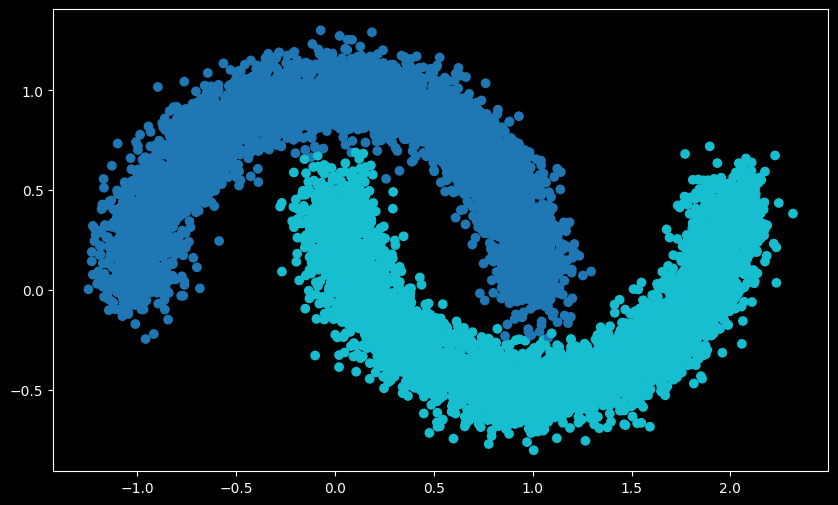

In [16]:
X, y = make_moons(n_samples=10_000, noise=0.1, random_state=88)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=88)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='tab10');

In [17]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((8000, 2), (8000,), (2000, 2), (2000,))

In [18]:
y_train_ohe = keras.utils.to_categorical(y_train, num_classes=2)
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=2)
y_train_ohe.shape, y_test_ohe.shape

((8000, 2), (2000, 2))

In [19]:
y_train_ohe[:5]

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.]])

In [20]:
model = keras.Sequential(name='MLP_2')
model.add(keras.layers.Input(shape=(2,)))
model.add(keras.layers.Dense(4, activation='relu'))
model.add(keras.layers.Dense(8, activation='relu'))
model.add(keras.layers.Dense(2, activation='softmax'))
model.summary()

Model: "MLP_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70 (280.00 B)

 Trainable params: 70 (280.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
opt = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=opt,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [22]:
history = model.fit(
    X_train, y_train_ohe,
    validation_split=0.2,
    epochs=25,
    batch_size=32
)

Epoch 1/25


I0000 00:00:1794305815.110347   42876 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_16024__.17


200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7405 - loss: 0.5380 - val_accuracy: 0.8612 - val_loss: 0.4127
Epoch 2/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8756 - loss: 0.3395 - val_accuracy: 0.8763 - val_loss: 0.2901
Epoch 3/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8913 - loss: 0.2592 - val_accuracy: 0.8881 - val_loss: 0.2364
Epoch 4/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9064 - loss: 0.2163 - val_accuracy: 0.9094 - val_loss: 0.1988
Epoch 5/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9244 - loss: 0.1816 - val_accuracy: 0.9244 - val_loss: 0.1668
Epoch 6/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9383 - loss: 0.1505 - val_accuracy: 0.9425 - val_loss: 0.1347
Epoch 7/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9539 - loss: 0.1194 - val_accuracy: 0.9575 - val_loss: 0.1029
Epoch 8/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9694 - loss: 0.0903 - val_accuracy: 0.9787 - val_

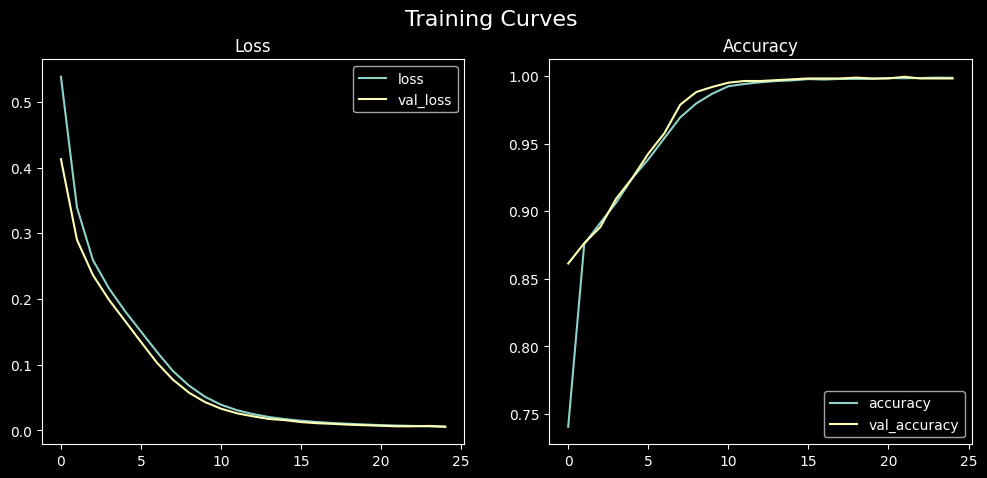

In [23]:
pd.DataFrame(history.history).columns
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(12,5))
pd.DataFrame(history.history).loc[:,['loss', 'val_loss']].plot(ax=ax1, title='Loss');  
pd.DataFrame(history.history).loc[:, ['accuracy', 'val_accuracy']].plot(ax=ax2, title='Accuracy');
fig.suptitle('Training Curves', fontsize=16);

# 3. Build a simple CNN

## Dataset

`datasets` gives access to specific datasets, such as:

Tabular:
- boston_housing
- california_housing

Computer Vision
- mnist
- fashion_mnist
- cifar10
- cifar100

NLP
- imdb
- reuters

In [24]:
from keras import datasets
(X_train, y_train), (X_test, y_test) = datasets.fashion_mnist.load_data()

In [25]:
X_train.shape

(60000, 28, 28)

### Exploring the dataset

Let's have look at some of the images

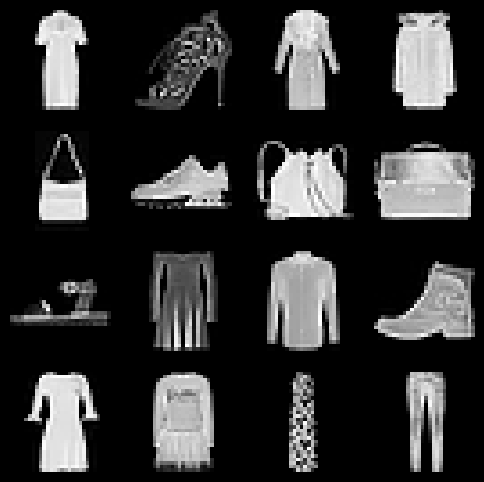

In [26]:
number_of_train_images = len(X_train)
number_of_train_images_to_show = 16
random_list_of_images_to_show = np.random.randint(0, number_of_train_images , number_of_train_images_to_show)

fig, axs = plt.subplots(4, 4, figsize=(6,6))
for i, ax in zip(random_list_of_images_to_show, axs.flatten()):
    ax.imshow(X_train[i], cmap='gray')
    ax.axis('off')
plt.show()

### Image intensity normalisation

Normalise the intensities:

In [27]:
X_test[0, 10:20, :10]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   1,   0,   2,   1],
       [  0,   0,   0,   0,   1,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   2,   4,   1,   0],
       [  0,   0,   2,   2,   1,   2,   0,   0,   0,   0],
       [  3,   0,   0,   0,   0,   0,   0,  21,  53,  92],
       [  0,   0,  23,  54,  65,  76,  85, 118, 128, 123],
       [  0,  68,  94,  90, 111, 114, 111, 114, 115, 127],
       [ 70, 169, 129, 104,  98, 100,  94,  97,  98, 102]], dtype=uint8)

In [28]:
X_train = X_train / 255.
X_test = X_test / 255.

In [29]:
X_train.shape, X_test.shape

((60000, 28, 28), (10000, 28, 28))

We have 60,000 training images and 10,000 test images, each of size (28, 28)

But a Convolutional Neural Network models need to be fed with images whose last dimension is the number of channels `(NUMBER_OF_IMAGES, HEIGHT, WIDTH, CHANNELS)`

The images are grayscale images i.e. they only have one channel, this is why the shape the each image is (28,28) and not (28,28,1) as the last dimension is not useful in general  

But in this case, we need to add it explicitely

In [30]:
from tensorflow.keras.backend import expand_dims

X_train = expand_dims(X_train, axis=-1)
X_test = expand_dims(X_test, axis=-1)

X_train.shape, X_test.shape

W0000 00:00:1794305857.768824   42424 cpu_allocator_impl.cc:82] Allocation of 376320000 exceeds 10% of free system memory.


(TensorShape([60000, 28, 28, 1]), TensorShape([10000, 28, 28, 1]))

### One Hot Encoding of Target/Class

In [31]:
y_train[:5]

array([9, 0, 0, 3, 0], dtype=uint8)

In [32]:
from tensorflow.keras.utils import to_categorical

y_train_ohe = to_categorical(y_train, num_classes=10)
y_test_ohe = to_categorical(y_test, num_classes=10)

In [33]:
y_train_ohe.shape, y_test_ohe.shape

((60000, 10), (10000, 10))

## Architecture

In [35]:
model = keras.Sequential(name="Fashion_MNIST_CNN")

model.add(keras.layers.Input(shape=(28, 28, 1), name='Input_Layer'))

### First Convolution & MaxPooling
model.add(keras.layers.Conv2D(8, (4,4), activation='relu', padding='same', name='L1_Conv'))
model.add(keras.layers.MaxPool2D(pool_size=(2,2)))

### Flattening
model.add(keras.layers.Flatten())

### One Fully Connected layer - "Fully Connected" is equivalent to saying "Dense"
model.add(keras.layers.Dense(10, activation='relu', name='L3_FC'))

### Last layer - Classification Layer with 10 outputs corresponding to 10 digits
model.add(keras.layers.Dense(10, activation='softmax', name='L4_Output'))

model.summary();

Model: "Fashion_MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1_Conv (Conv2D)                │ (None, 28, 28, 8)      │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3_FC (Dense)                   │ (None, 10)             │        15,690 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L4_Output (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,936 (62.25 KB)

 Trainable params: 15,936 (62.25 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
### Model compilation
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam', 
    metrics=['accuracy']
)

## Training

In [37]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(patience = 5, restore_best_weights = True)

history = model.fit(
    X_train, 
    y_train_ohe,
    validation_split = 0.3,
    batch_size = 32,
    epochs = 25,
    callbacks = [es],
    verbose = 1
)


Epoch 1/25


I0000 00:00:1794305880.669296   42877 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_43330__.25


1308/1313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6912 - loss: 0.9520

I0000 00:00:1794305886.268089   42877 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_43330__.25


1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7856 - loss: 0.6510 - val_accuracy: 0.8440 - val_loss: 0.4416
Epoch 2/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8564 - loss: 0.4137 - val_accuracy: 0.8605 - val_loss: 0.3923
Epoch 3/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8732 - loss: 0.3659 - val_accuracy: 0.8670 - val_loss: 0.3682
Epoch 4/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8813 - loss: 0.3375 - val_accuracy: 0.8765 - val_loss: 0.3419
Epoch 5/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8879 - loss: 0.3166 - val_accuracy: 0.8863 - val_loss: 0.3225
Epoch 6/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8927 - loss: 0.3005 - val_accuracy: 0.8818 - val_loss: 0.3316
Epoch 7/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8974 - loss: 0.2884 - val_accuracy: 0.8855 - val_loss: 0.3212
Epoch 8/25
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9014 - loss: 0.2767 - val_accura

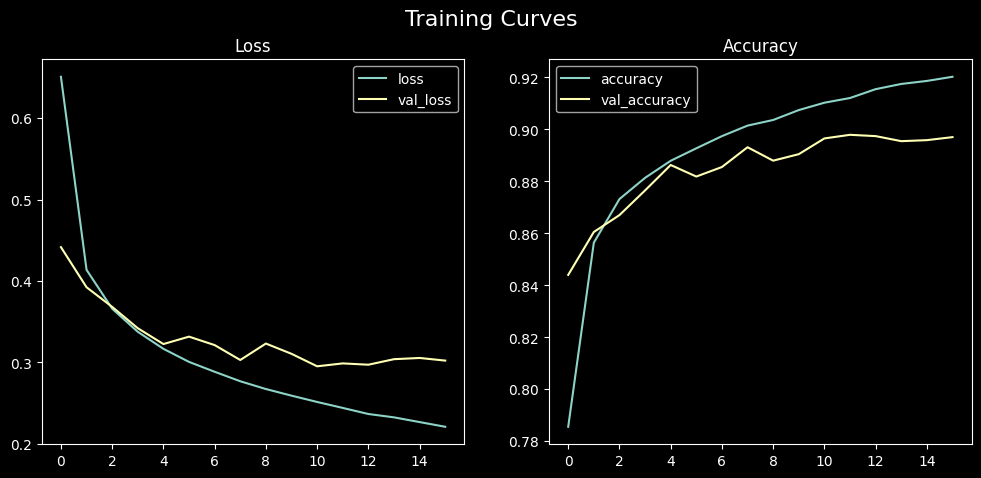

In [38]:
pd.DataFrame(history.history).columns
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(12,5))
pd.DataFrame(history.history).loc[:,['loss', 'val_loss']].plot(ax=ax1, title='Loss');  
pd.DataFrame(history.history).loc[:, ['accuracy', 'val_accuracy']].plot(ax=ax2, title='Accuracy');
fig.suptitle('Training Curves', fontsize=16);

## Example with color images

In [39]:
from keras import datasets
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

In [40]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((50000, 32, 32, 3), (50000, 1), (10000, 32, 32, 3), (10000, 1))

### Exploring the dataset

Let's have look at some of the images

In [41]:
cls_nb2cls_name = {
    0: 'airplane',
    1: 'automobile',
    2: 'bird',
    3: 'cat',
    4: 'deer',
    5: 'dog',
    6: 'frog',
    7: 'horse',
    8: 'ship',
    9: 'truck'
}

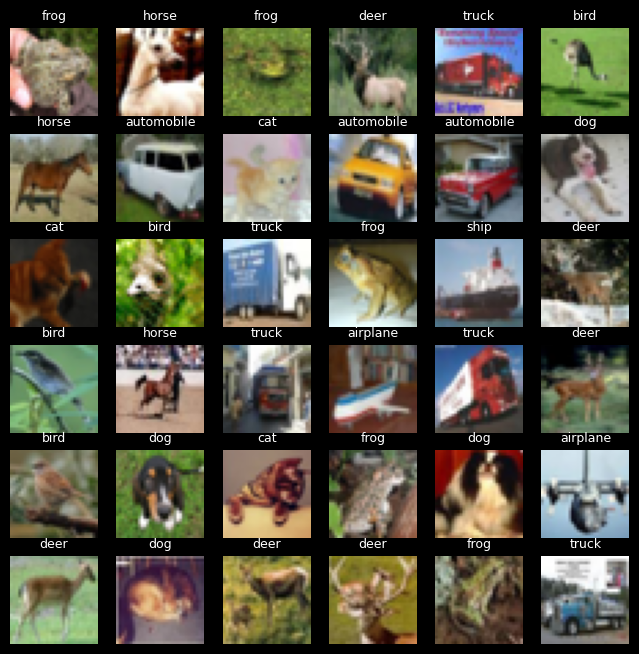

In [43]:
number_of_train_images = len(X_train)
number_of_train_images_to_show = 36
random_list_of_images_to_show = np.random.randint(0, number_of_train_images , number_of_train_images_to_show)

fig, axs = plt.subplots(6, 6, figsize=(8,8))
for i, ax in zip(random_list_of_images_to_show, axs.flatten()):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f"{cls_nb2cls_name[y_train[i][0]]}", fontsize=9)
    ax.axis('off')
plt.show()

### Image intensity normalisation

Let's check some intensity values for one color channel:

In [44]:
X_train[0, :5, :5, 0]

array([[ 59,  43,  50,  68,  98],
       [ 16,   0,  18,  51,  88],
       [ 25,  16,  49,  83, 110],
       [ 33,  38,  87, 106, 115],
       [ 50,  59, 102, 127, 124]], dtype=uint8)

The image in in uint8, we need to normalise the intensities to float between 0 and 1.

In [45]:
X_train = X_train / 255.
X_test = X_test / 255.

In [46]:
X_train[0, :5, :5, 0]

array([[0.23137255, 0.16862745, 0.19607843, 0.26666667, 0.38431373],
       [0.0627451 , 0.        , 0.07058824, 0.2       , 0.34509804],
       [0.09803922, 0.0627451 , 0.19215686, 0.3254902 , 0.43137255],
       [0.12941176, 0.14901961, 0.34117647, 0.41568627, 0.45098039],
       [0.19607843, 0.23137255, 0.4       , 0.49803922, 0.48627451]])

### One Hot Encoding of Target/Class

In [47]:
from tensorflow.keras.utils import to_categorical

y_train_ohe = to_categorical(y_train, num_classes=10)
y_test_ohe = to_categorical(y_test, num_classes=10)

In [48]:
y_train_ohe.shape, y_test_ohe.shape

((50000, 10), (10000, 10))

## Architecture

In [49]:
model = keras.Sequential(name="MNIST_CNN")

model.add(keras.layers.Input(shape=(32, 32, 3), name='Input_Layer'))

### First Convolution & MaxPooling
model.add(keras.layers.Conv2D(8, (5,5), activation='relu', padding='same', name='L1_Conv'))
model.add(keras.layers.MaxPool2D(pool_size=(2,2)))

### Second Convolution & MaxPooling
model.add(keras.layers.Conv2D(16, (4,4), activation='relu', padding='same', name='L2_Conv'))
model.add(keras.layers.MaxPool2D(pool_size=(2,2)))

### Third Convolution & MaxPooling
model.add(keras.layers.Conv2D(32, (3,3), activation='relu', padding='same', name='L3_Conv'))
model.add(keras.layers.MaxPool2D(pool_size=(2,2)))

### Flattening
model.add(keras.layers.Flatten())

### One Fully Connected layer - "Fully Connected" is equivalent to saying "Dense"
model.add(keras.layers.Dense(10, activation='relu', name='L3_FC'))

### Last layer - Classification Layer with 10 outputs corresponding to 10 digits
model.add(keras.layers.Dense(10, activation='softmax', name='L4_Output'))

model.summary();

Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1_Conv (Conv2D)                │ (None, 32, 32, 8)      │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2_Conv (Conv2D)                │ (None, 16, 16, 16)     │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3_Conv (Conv2D)                │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3_FC (Dense)                   │ (None, 10)             │         5,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L4_Output (Dense)               │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,552 (49.03 KB)

 Trainable params: 12,552 (49.03 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
### Model compilation
opt = keras.optimizers.Adam(learning_rate=0.001)
model.compile(
    optimizer=opt,   # we also could use optimizer='adam', but then we cannot control the learning rate
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Training

In [51]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(patience = 5, restore_best_weights = True)

history = model.fit(
    X_train, 
    y_train_ohe,
    validation_split = 0.3,
    batch_size = 32,
    epochs = 50,
    callbacks = [es],
    verbose = 1
)


W0000 00:00:1794306015.517223   42424 cpu_allocator_impl.cc:82] Allocation of 430080000 exceeds 10% of free system memory.
W0000 00:00:1794306016.148058   42424 cpu_allocator_impl.cc:82] Allocation of 430080000 exceeds 10% of free system memory.


Epoch 1/50


I0000 00:00:1794306017.061269   42878 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_166226__.43


1084/1094 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2243 - loss: 2.0792

I0000 00:00:1794306023.880255   42878 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_166226__.43


1094/1094 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.2991 - loss: 1.8786 - val_accuracy: 0.3838 - val_loss: 1.6649
Epoch 2/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4424 - loss: 1.5062 - val_accuracy: 0.4793 - val_loss: 1.4385
Epoch 3/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5008 - loss: 1.3601 - val_accuracy: 0.5079 - val_loss: 1.3373
Epoch 4/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5351 - loss: 1.2776 - val_accuracy: 0.5071 - val_loss: 1.3884
Epoch 5/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5617 - loss: 1.2097 - val_accuracy: 0.5578 - val_loss: 1.2312
Epoch 6/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5808 - loss: 1.1591 - val_accuracy: 0.5717 - val_loss: 1.2053
Epoch 7/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5957 - loss: 1.1176 - val_accuracy: 0.5778 - val_loss: 1.1751
Epoch 8/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6088 - loss: 1.0923 - val_accur

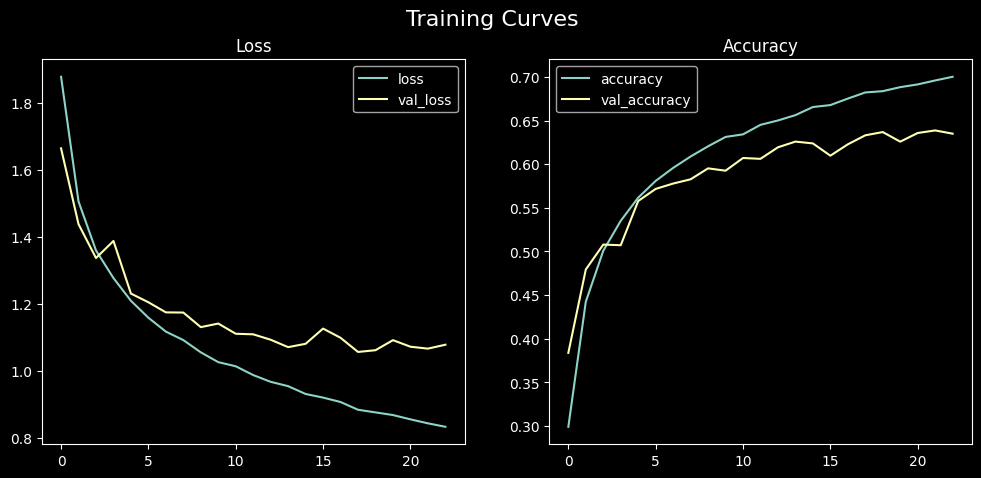

In [52]:
pd.DataFrame(history.history).columns
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(12,5))
pd.DataFrame(history.history).loc[:,['loss', 'val_loss']].plot(ax=ax1, title='Loss');  
pd.DataFrame(history.history).loc[:, ['accuracy', 'val_accuracy']].plot(ax=ax2, title='Accuracy');
fig.suptitle('Training Curves', fontsize=16);

In [53]:
model.evaluate(X_test, y_test_ohe)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6303 - loss: 1.0585


[1.0584794282913208, 0.630299985408783]